KAVYASHREE ENG24CS0094 B1 03/11/2026 experiment 7:Decision Tree

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


In [5]:
df = pd.read_csv("diabetes (6).csv")
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [6]:
df.shape

(768, 9)

In [7]:
print("\nColumns:", list(df.columns))


Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [9]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [11]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [12]:
df.isnull().sum()

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

In [14]:
zero_as_missing_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("\nZero-value counts (treated as missing) before cleaning:")
print(df[zero_as_missing_cols].eq(0).sum())

for col in zero_as_missing_cols:
    median_value = df.loc[df[col] != 0, col].median()   # median excluding the 0s
    df[col] = df[col].replace(0, median_value)

print("\nZero-value counts after cleaning:")
print(df[zero_as_missing_cols].eq(0).sum())



Zero-value counts (treated as missing) before cleaning:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Zero-value counts after cleaning:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


In [15]:
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("\nTarget distribution:\n", y.value_counts())


Target distribution:
 Outcome
0    500
1    268
Name: count, dtype: int64


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\nTraining samples: {X_train.shape[0]}")
print(f"Testing samples : {X_test.shape[0]}")



Training samples: 614
Testing samples : 154


In [18]:
dt_model = DecisionTreeClassifier(
criterion="gini",
max_depth=4, 
min_samples_split=10, 
min_samples_leaf=5, 
random_state=42
)
dt_model.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=4, min_samples_leaf=5, min_samples_split=10,
                       random_state=42)

In [19]:
y_pred = dt_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n", cm)



Test Accuracy: 79.87%

Classification Report:

              precision    recall  f1-score   support

 No Diabetes       0.85      0.84      0.84       100
    Diabetes       0.71      0.72      0.72        54

    accuracy                           0.80       154
   macro avg       0.78      0.78      0.78       154
weighted avg       0.80      0.80      0.80       154

Confusion Matrix:
 [[84 16]
 [15 39]]


In [20]:
cv_scores = cross_val_score(dt_model, X, y, cv=5)
print(f"\n5-Fold Cross-Validation Accuracy: {cv_scores.mean()*100:.2f}% "
      f"(+/- {cv_scores.std()*100:.2f}%)")



5-Fold Cross-Validation Accuracy: 73.31% (+/- 4.02%)


In [21]:
param_grid = {
    "max_depth": [3, 4, 5, 6, 8, None],
    "criterion": ["gini", "entropy"],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 3, 5]
}

grid_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

print("\nBest parameters found:", grid_search.best_params_)
print(f"Best cross-validation accuracy: {grid_search.best_score_*100:.2f}%")

best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test)
print(f"Tuned model test accuracy: {accuracy_score(y_test, y_pred_best)*100:.2f}%")



Best parameters found: {'criterion': 'entropy', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best cross-validation accuracy: 74.77%
Tuned model test accuracy: 68.83%


In [22]:
importances = pd.Series(best_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)
print("\nFeature Importances (tuned model):\n", importances)



Feature Importances (tuned model):
 Glucose                     0.695568
BMI                         0.269789
Insulin                     0.034643
Pregnancies                 0.000000
BloodPressure               0.000000
SkinThickness               0.000000
DiabetesPedigreeFunction    0.000000
Age                         0.000000
dtype: float64



Plots saved as 'diabetes_dt_results.png'


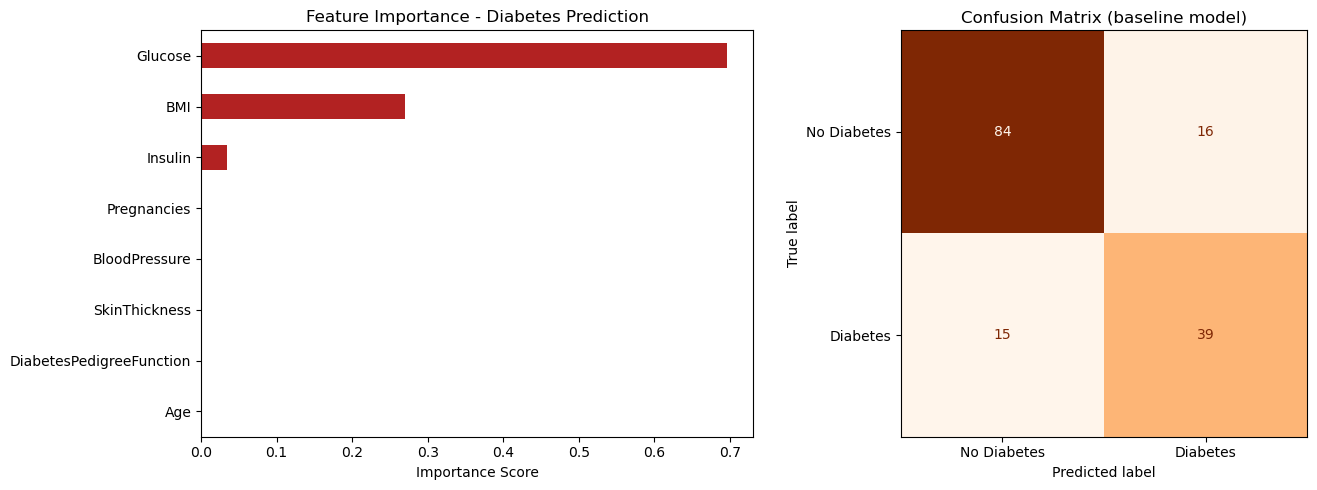

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

importances.plot(kind="barh", ax=axes[0], color="firebrick")
axes[0].invert_yaxis()
axes[0].set_title("Feature Importance - Diabetes Prediction")
axes[0].set_xlabel("Importance Score")

disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=["No Diabetes", "Diabetes"])
disp.plot(ax=axes[1], cmap="Oranges", colorbar=False)
axes[1].set_title("Confusion Matrix (baseline model)")
plt.tight_layout()
plt.savefig("diabetes_dt_results.png", dpi=150)
print("\nPlots saved as 'diabetes_dt_results.png'")


Tree diagram saved as 'diabetes_tree_structure.png'


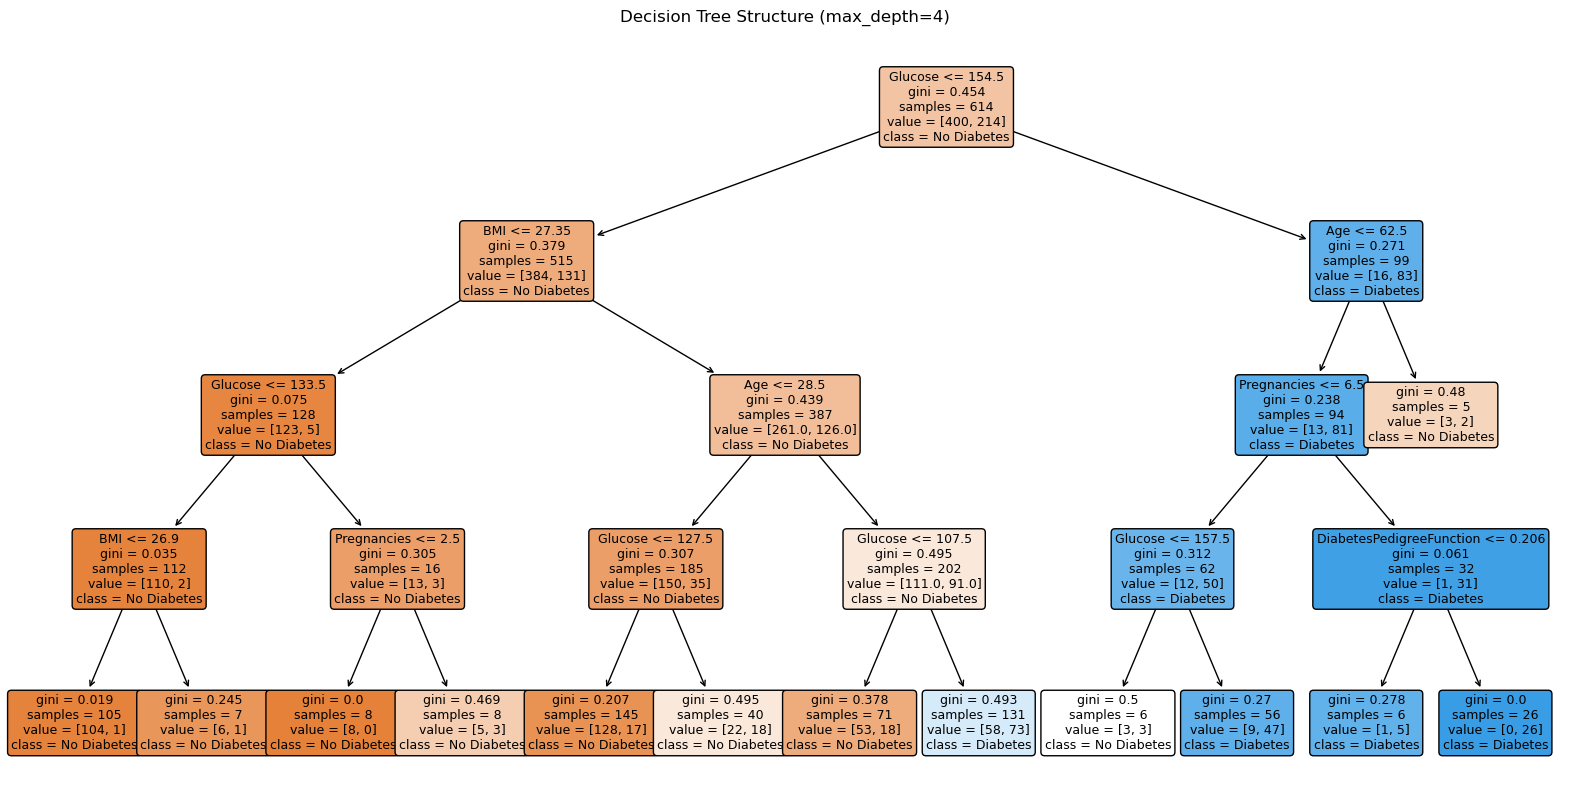

In [24]:
plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["No Diabetes", "Diabetes"],
    filled=True,
    rounded=True,
    fontsize=9
)
plt.title("Decision Tree Structure (max_depth=4)")
plt.savefig("diabetes_tree_structure.png", dpi=150, bbox_inches="tight")
print("Tree diagram saved as 'diabetes_tree_structure.png'")


In [25]:
new_patient = pd.DataFrame({
    "Pregnancies": [2],
    "Glucose": [150],
    "BloodPressure": [80],
    "SkinThickness": [30],
    "Insulin": [100],
    "BMI": [33.5],
    "DiabetesPedigreeFunction": [0.6],
    "Age": [45]
})
prediction = best_model.predict(new_patient)[0]
probability = best_model.predict_proba(new_patient)[0]

print(f"\nNew patient prediction: {'Diabetes' if prediction == 1 else 'No Diabetes'}")
print(f"Probability of diabetes: {probability[1]*100:.2f}%")



New patient prediction: No Diabetes
Probability of diabetes: 39.59%
